# Lab 4 — Séquences et texte : RNN, LSTM, GRU

**ENSIM · 5A ASTRE · De l'IA au LLM agentique · Séance 4**
*Bassem Ben Hamed & Ali Khalfallah*

Ce lab se fait **en autonomie, après la séance 4**. Il valide la séance : chaque exemple numérique des diapositives est recalculé ici, puis mis en œuvre sur le fil rouge B (classification d'intention sur MASSIVE fr-FR) et sur un petit modèle de langage par caractères entraîné sur le noyau FreeRTOS.

## Objectifs

À la fin du lab, vous savez :

1. transformer du texte en nombres : **tokenisation** par mot, par caractère ou par sous-mot (BPE), **one-hot** puis **embedding** ;
2. dérouler un **RNN** à la main, et **mesurer** le gradient qui s'évanouit dans le temps ;
3. calculer un pas de **LSTM** et de **GRU**, et compter leurs **paramètres** ;
4. entraîner un RNN, un LSTM et un GRU sur **MASSIVE fr-FR** et comparer exactitude, paramètres et temps ;
5. entraîner un LSTM **par caractères** et voir l'effet de la **température** (préparation de la séance 6) ;
6. estimer le coût d'un LSTM sur un **STM32F446** (taille, MAC, latence, mémoire d'état).

## Prérequis et environnement

- Séances 2 et 3 (neurone, MLP, rétropropagation), notions de PyTorch.
- **Google Colab gratuit.** Un GPU T4 est recommandé (Exécution → Modifier le type d'exécution), mais le lab tourne aussi sur CPU : le code choisit le périphérique dans l'ordre CUDA, MPS, CPU et réduit la taille du modèle par caractères sur CPU. Durée d'exécution : environ 6 minutes et demie sur un Mac M4 Pro (GPU MPS) ; non mesurée sur un T4.

## Plan

| Partie | Contenu |
|---|---|
| 1 | Rappel des formules |
| A | Recalculer les exemples numériques des diapositives |
| B | Expériences : MASSIVE (RNN, LSTM, GRU), gradient dans le temps, LSTM par caractères, cible embarquée |
| C | Exercices de validation, vérifiés automatiquement |
| | Corrigé |

> **Données** : *Amazon MASSIVE 1.1*, partition fr-FR (FitzGerald et al., 2022), licence CC BY 4.0, avec la partition officielle `train` (11 514 phrases), `dev` (2 033) et `test` (2 974). 60 intentions, dont 9 intentions `iot_*` (objets connectés). Noyau **FreeRTOS** (`FreeRTOS-Kernel`, licence MIT) pour le modèle par caractères.

## 1. Rappel des formules

| Notion | Formule |
|---|---|
| RNN | $\mathbf{h}_t = \tanh\!\big(W_{xh}\,\mathbf{x}_t + W_{hh}\,\mathbf{h}_{t-1} + \mathbf{b}\big)$ |
| Gradient dans le temps | $\dfrac{\partial \mathbf{h}_T}{\partial \mathbf{h}_1} = \prod_{t=2}^{T} \mathrm{diag}\big(1-\mathbf{h}_t^2\big)\,W_{hh}$ |
| LSTM | $f,i,o = \sigma(\cdot)$, $\;\tilde c = \tanh(\cdot)$, $\;c_t = f\,c_{t-1} + i\,\tilde c$, $\;h_t = o\,\tanh(c_t)$ |
| GRU (convention PyTorch) | $h_t = (1-z)\,n + z\,h_{t-1}$ |
| Paramètres (PyTorch) | RNN : $h(d+h+2)$ ; GRU : $3h(d+h+2)$ ; LSTM : $4h(d+h+2)$ |
| MAC par pas de temps | RNN : $h(d+h)$ ; GRU : $3h(d+h)$ ; LSTM : $4h(d+h)$ |
| Attention (Bahdanau) | $\alpha_j = \mathrm{softmax}(s_j)$, $\;\mathbf{c} = \sum_j \alpha_j\,\mathbf{h}_j$ |
| Similarité cosinus | $\cos(\mathbf{u},\mathbf{v}) = \dfrac{\mathbf{u}\cdot\mathbf{v}}{\lVert\mathbf{u}\rVert\,\lVert\mathbf{v}\rVert}$ |
| Température | $p_k = \mathrm{softmax}(z_k / T)$ |
| Bits par caractère | $\mathrm{bpc} = \mathcal{L}_{\text{CE}} / \ln 2$ |

Dans les formules des paramètres, $d$ est la dimension d'entrée, $h$ la taille de l'état caché, et le « +2 » vient des deux vecteurs de biais que PyTorch alloue par porte.

### Installation et imports

Sur Colab, `numpy`, `pandas`, `matplotlib`, `scikit-learn` et `torch` sont déjà installés. `tiktoken` est installé à la demande.

In [1]:
try:
    import tiktoken
except ImportError:
    %pip install -q tiktoken
    import tiktoken

import collections, io, json, math, os, re, tarfile, tempfile, time, urllib.request, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F

warnings.filterwarnings("ignore")
np.set_printoptions(precision=4, suppress=True)
plt.rcParams.update({"figure.figsize": (8, 4), "axes.grid": True, "grid.alpha": 0.3})
SEED = 42
torch.manual_seed(SEED); np.random.seed(SEED)
T0 = time.time()
CACHE = os.path.join(tempfile.gettempdir(), "lab4_cache")   # téléchargements, hors du dossier du notebook
os.makedirs(CACHE, exist_ok=True)

def choisir_device():
    if torch.cuda.is_available():
        return torch.device("cuda")
    if torch.backends.mps.is_available():
        return torch.device("mps")
    return torch.device("cpu")
DEVICE = choisir_device()
print("torch", torch.__version__, "| périphérique :", DEVICE)

def sigmoide(z):
    return 1.0 / (1.0 + np.exp(-z))

def softmax_np(z):
    z = np.asarray(z, dtype=float)
    e = np.exp(z - z.max())
    return e / e.sum()

def cosinus(u, v):
    u, v = np.asarray(u, dtype=float), np.asarray(v, dtype=float)
    return float(u @ v / (np.linalg.norm(u) * np.linalg.norm(v)))

torch 2.10.0 | périphérique : mps


## Partie A — Recalculer les exemples des diapositives

Chaque cellule reprend un exemple numérique de la séance 4. Les valeurs doivent être identiques à celles des diapositives.

### A1. Tokenisation : mots, caractères, sous-mots

La phrase de la diapositive : « allume la lumière du salon ». On compte ses unités selon la méthode, puis on applique le **BPE** (*byte pair encoding*) à un corpus jouet : à chaque étape, on fusionne la paire de symboles la plus fréquente (en cas d'égalité, la première rencontrée).

In [2]:
phrase = "allume la lumière du salon"
enc = tiktoken.get_encoding("cl100k_base")
ids = enc.encode(phrase)
print(f"mots : {len(phrase.split())}   caractères : {len(phrase)}   sous-mots (cl100k_base, GPT-4) : {len(ids)}")
print("sous-mots :", [enc.decode([i]) for i in ids])

def bpe(corpus, k):
    """corpus : {mot: fréquence}. Renvoie les k premières fusions et le corpus segmenté."""
    mots = {tuple(m): f for m, f in corpus.items()}
    fusions = []
    for _ in range(k):
        paires = collections.Counter()
        for m, f in mots.items():
            for a, b in zip(m, m[1:]):
                paires[(a, b)] += f
        (a, b), n = max(paires.items(), key=lambda kv: kv[1])     # max renvoie la première paire maximale
        fusions.append((a, b, n))
        nouveau = {}
        for m, f in mots.items():
            out, i = [], 0
            while i < len(m):
                if i < len(m) - 1 and m[i] == a and m[i + 1] == b:
                    out.append(a + b); i += 2
                else:
                    out.append(m[i]); i += 1
            nouveau[tuple(out)] = nouveau.get(tuple(out), 0) + f
        mots = nouveau
    return fusions, mots

corpus_jouet = {"allume": 4, "allumer": 3, "éteins": 3, "éteindre": 2}
fusions, seg = bpe(corpus_jouet, 8)
for k, (a, b, n) in enumerate(fusions, 1):
    print(f"fusion {k} : {a!r} + {b!r} -> {a + b!r}   (paire vue {n} fois)")
print("corpus segmenté :", {"".join(m) if len(m) == 1 else " ".join(m): f for m, f in seg.items()})

mots : 5   caractères : 26   sous-mots (cl100k_base, GPT-4) : 7
sous-mots : ['all', 'ume', ' la', ' lum', 'ière', ' du', ' salon']
fusion 1 : 'a' + 'l' -> 'al'   (paire vue 7 fois)
fusion 2 : 'al' + 'l' -> 'all'   (paire vue 7 fois)
fusion 3 : 'all' + 'u' -> 'allu'   (paire vue 7 fois)
fusion 4 : 'allu' + 'm' -> 'allum'   (paire vue 7 fois)
fusion 5 : 'allum' + 'e' -> 'allume'   (paire vue 7 fois)
fusion 6 : 'é' + 't' -> 'ét'   (paire vue 5 fois)
fusion 7 : 'ét' + 'e' -> 'éte'   (paire vue 5 fois)
fusion 8 : 'éte' + 'i' -> 'étei'   (paire vue 5 fois)
corpus segmenté : {'allume': 4, 'allume r': 3, 'étei n s': 3, 'étei n d r e': 2}


### A2. One-hot et embeddings

Un mot parmi $V$ est un vecteur **one-hot** de dimension $V$, presque tout à zéro. Un **embedding** le remplace par un vecteur dense de dimension $d \ll V$ : c'est une ligne d'une matrice $E \in \mathbb{R}^{V\times d}$, apprise avec le reste du réseau. Les vecteurs ci-dessous sont **choisis à la main** pour l'illustration ; les voisins appris sont dans la partie B.

In [3]:
V, d_emb = 10_000, 64
print(f"one-hot : {V} dimensions par mot ; embedding : {d_emb} dimensions, soit {V / d_emb:.0f} fois moins")
print(f"matrice d'embeddings : {V} x {d_emb} = {V * d_emb:,} paramètres".replace(",", " "))

E = {"allume": (0.9, 0.3), "éteins": (0.8, 0.4), "salon": (-0.5, 0.8), "cuisine": (-0.4, 0.9)}
for a, b in [("allume", "éteins"), ("salon", "cuisine"), ("allume", "salon")]:
    print(f"cos({a}, {b}) = {cosinus(E[a], E[b]):+.3f}")

one-hot : 10000 dimensions par mot ; embedding : 64 dimensions, soit 156 fois moins
matrice d'embeddings : 10000 x 64 = 640 000 paramètres
cos(allume, éteins) = +0.990
cos(salon, cuisine) = +0.990
cos(allume, salon) = -0.235


### A3. Un RNN déroulé sur trois pas de temps

Mêmes poids que le réseau 2-2-1 de la séance 3 pour l'entrée : $W_{xh}$, plus une matrice récurrente $W_{hh}$ et des biais nuls. Entrées $\mathbf{x}_1 = (1, 0)$, $\mathbf{x}_2 = (0, 1)$, $\mathbf{x}_3 = (1, 1)$, état initial nul. On compare avec `nn.RNN` de PyTorch, dont on fixe les poids.

In [4]:
Wxh = np.array([[0.5, -0.5], [0.3, 0.8]])
Whh = np.array([[0.4, 0.1], [-0.2, 0.3]])
b = np.zeros(2)
X = np.array([[1.0, 0.0], [0.0, 1.0], [1.0, 1.0]])

h = np.zeros(2)
H_main = []
for t, x in enumerate(X, 1):
    z = Wxh @ x + Whh @ h + b
    h = np.tanh(z)
    H_main.append(h)
    print(f"t = {t} : z = {z}   h = {h}")

rnn = nn.RNN(2, 2, nonlinearity="tanh", batch_first=True)
with torch.no_grad():
    rnn.weight_ih_l0.copy_(torch.tensor(Wxh)); rnn.weight_hh_l0.copy_(torch.tensor(Whh))
    rnn.bias_ih_l0.zero_(); rnn.bias_hh_l0.zero_()
    sortie, _ = rnn(torch.tensor(X, dtype=torch.float32)[None])
print("nn.RNN       :", sortie[0].numpy().round(4).tolist())
print("écart maximal avec le calcul à la main :", float(np.abs(sortie[0].numpy() - np.array(H_main)).max()))

t = 1 : z = [0.5 0.3]   h = [0.4621 0.2913]
t = 2 : z = [-0.286  0.795]   h = [-0.2785  0.6612]
t = 3 : z = [-0.0453  1.3541]   h = [-0.0452  0.875 ]
nn.RNN       : [[0.46209999918937683, 0.2912999987602234], [-0.2784999907016754, 0.6611999869346619], [-0.04520000144839287, 0.875]]
écart maximal avec le calcul à la main : 2.2845900393697605e-08


### A4. Le gradient qui s'évanouit : un produit de facteurs

Le gradient de $\mathbf{h}_T$ par rapport à $\mathbf{h}_1$ est un produit de $T-1$ facteurs. Dans le cas scalaire, avec une dérivée de $\tanh$ voisine de 1, le facteur vaut $w$ : le produit vaut $w^{T-1}$ (on prend ici $T = 10$ facteurs et $T = 20$ facteurs, comme sur la diapositive).

In [5]:
for w in (0.5, 1.0, 1.5):
    print(f"w = {w} :  w^10 = {w ** 10:.3g}   w^20 = {w ** 20:.3g}")
print(f"0,9^50 = {0.9 ** 50:.3g}    1,1^50 = {1.1 ** 50:.3g}")

w = 0.5 :  w^10 = 0.000977   w^20 = 9.54e-07
w = 1.0 :  w^10 = 1   w^20 = 1
w = 1.5 :  w^10 = 57.7   w^20 = 3.33e+03
0,9^50 = 0.00515    1,1^50 = 117


### A5. Un pas de LSTM et un pas de GRU

On part des pré-activations (déjà calculées à partir de $\mathbf{x}_t$ et $h_{t-1}$) pour un LSTM à **une seule unité** : $z_f = 2$, $z_i = 0$, $z_o = 1$, $z_g = 1$, avec $c_{t-1} = 0{,}8$. Pour le GRU : $z = 0{,}7$, $n = 0{,}6$, $h_{t-1} = 0{,}5$.

In [6]:
zf, zi, zo, zg, c_prev = 2.0, 0.0, 1.0, 1.0, 0.8
f, i, o, g = sigmoide(zf), sigmoide(zi), sigmoide(zo), np.tanh(zg)
c = f * c_prev + i * g
h_lstm = o * np.tanh(c)
print(f"portes : f = {f:.4f}, i = {i:.4f}, o = {o:.4f}, candidat g = {g:.4f}")
print(f"c_t = f c_(t-1) + i g = {f:.4f} x {c_prev} + {i:.1f} x {g:.4f} = {c:.4f}")
print(f"h_t = o tanh(c_t) = {o:.4f} x {np.tanh(c):.4f} = {h_lstm:.4f}")

z_u, n_cand, h_prev = 0.7, 0.6, 0.5
h_gru = (1 - z_u) * n_cand + z_u * h_prev
print(f"\nGRU : h_t = (1 - z) n + z h_(t-1) = {1 - z_u:.1f} x {n_cand} + {z_u} x {h_prev} = {h_gru:.2f}")

portes : f = 0.8808, i = 0.5000, o = 0.7311, candidat g = 0.7616
c_t = f c_(t-1) + i g = 0.8808 x 0.8 + 0.5 x 0.7616 = 1.0854
h_t = o tanh(c_t) = 0.7311 x 0.7952 = 0.5813

GRU : h_t = (1 - z) n + z h_(t-1) = 0.3 x 0.6 + 0.7 x 0.5 = 0.53


### A6. Combien de paramètres ?

On compare la formule avec PyTorch, pour les trois tailles utilisées dans les diapositives et dans ce lab : $(d, h) = (64, 128)$ pour MASSIVE, $(16, 32)$ pour la cible embarquée, $(14, 32)$ pour les 14 capteurs de C-MAPSS (séance 3).

In [7]:
def nb_params(model):
    return sum(p.numel() for p in model.parameters())

FACTEUR = {"rnn": 1, "gru": 3, "lstm": 4}
CLASSES = {"rnn": nn.RNN, "gru": nn.GRU, "lstm": nn.LSTM}
lignes = []
for d, h in [(64, 128), (16, 32), (14, 32)]:
    ligne = {"d": d, "h": h}
    for cell in ("rnn", "gru", "lstm"):
        formule = FACTEUR[cell] * h * (d + h + 2)
        torch_n = nb_params(CLASSES[cell](d, h, batch_first=True))
        assert formule == torch_n
        ligne[cell.upper()] = torch_n
    lignes.append(ligne)
print(pd.DataFrame(lignes).to_string(index=False))
print("\nLa formule coïncide avec PyTorch (assertion vérifiée). Le LSTM a 4 fois plus de paramètres qu'un RNN, le GRU 3 fois plus.")

 d   h   RNN   GRU  LSTM
64 128 24832 74496 99328
16  32  1600  4800  6400
14  32  1536  4608  6144

La formule coïncide avec PyTorch (assertion vérifiée). Le LSTM a 4 fois plus de paramètres qu'un RNN, le GRU 3 fois plus.


### A7. L'attention de Bahdanau sur trois états

Trois états d'encodeur $\mathbf{h}_1 = (1, 0)$, $\mathbf{h}_2 = (0, 1)$, $\mathbf{h}_3 = (1, 1)$ et des scores d'alignement $s = (2, 1, 0)$ avec l'état courant du décodeur. Les poids d'attention sont le softmax des scores ; le contexte est la moyenne pondérée des états.

In [8]:
scores = np.array([2.0, 1.0, 0.0])
H_enc = np.array([[1.0, 0.0], [0.0, 1.0], [1.0, 1.0]])
alpha = softmax_np(scores)
contexte = alpha @ H_enc
print("poids d'attention alpha :", alpha, " somme =", alpha.sum())
print("contexte c = sum alpha_j h_j :", contexte)

poids d'attention alpha : [0.6652 0.2447 0.09  ]  somme = 0.9999999999999999
contexte c = sum alpha_j h_j : [0.7553 0.3348]


### A8. Un LSTM sur cible embarquée

Le LSTM de la diapositive « Et sur cible embarquée ? » : $d = 16$ entrées, $h = 32$ unités, une fenêtre de $T = 30$ pas de temps. Référence : STM32F446, Cortex-M4 à 180 MHz, 512 Ko de Flash, 128 Ko de SRAM. On suppose 2 à 4 cycles d'horloge par MAC (ordre de grandeur, à mesurer sur la cible).

In [9]:
d, h, T = 16, 32, 30
FREQ, FLASH, SRAM = 180e6, 512 * 1024, 128 * 1024
P = FACTEUR["lstm"] * h * (d + h + 2)
mac_pas = 4 * h * (d + h)
mac_fenetre = mac_pas * T
print(f"paramètres : {P} -> float32 {4 * P / 1000:.1f} ko ({4 * P / FLASH:.1%} de la Flash), int8 {P / 1000:.1f} ko")
print(f"MAC par pas de temps : {mac_pas}   MAC pour {T} pas : {mac_fenetre}")
print(f"latence estimée : {mac_fenetre * 2 / FREQ * 1e3:.2f} à {mac_fenetre * 4 / FREQ * 1e3:.2f} ms")
print(f"mémoire d'état (h et c, float32) : {2 * h * 4} octets, constante quelle que soit la longueur de la séquence")

paramètres : 6400 -> float32 25.6 ko (4.9% de la Flash), int8 6.4 ko
MAC par pas de temps : 6144   MAC pour 30 pas : 184320
latence estimée : 2.05 à 4.10 ms
mémoire d'état (h et c, float32) : 256 octets, constante quelle que soit la longueur de la séquence


## Partie B — Expériences

### B1. Le fil rouge B : MASSIVE fr-FR

On télécharge l'archive officielle (40 Mo) et on ne lit que `fr-FR.jsonl`. **Repli** si le site est indisponible : la version Parquet du jeu sur Hugging Face. Le fichier est mis en cache dans un dossier temporaire.

In [10]:
URL_MASSIVE = "https://amazon-massive-nlu-dataset.s3.amazonaws.com/amazon-massive-dataset-1.1.tar.gz"
URL_PARQUET = "https://huggingface.co/datasets/AmazonScience/massive/resolve/refs%2Fconvert%2Fparquet/fr-FR/{split}/0000.parquet"
FICHIER_FR = os.path.join(CACHE, "massive_fr-FR.jsonl")

def charger_massive():
    if os.path.exists(FICHIER_FR):
        with open(FICHIER_FR, encoding="utf-8") as f:
            return [json.loads(l) for l in f], "cache local"
    try:
        with urllib.request.urlopen(URL_MASSIVE, timeout=180) as r:
            archive = r.read()
        with tarfile.open(fileobj=io.BytesIO(archive), mode="r:gz") as tf:
            texte = tf.extractfile("1.1/data/fr-FR.jsonl").read().decode("utf-8")
        source = "archive officielle"
    except Exception as e:
        print("Archive officielle indisponible :", type(e).__name__, "- repli sur la version Parquet")
        import pyarrow.parquet as pq
        lignes = []
        for split, partition in [("train", "train"), ("validation", "dev"), ("test", "test")]:
            with urllib.request.urlopen(URL_PARQUET.format(split=split), timeout=180) as r:
                t = pq.read_table(io.BytesIO(r.read()))
            noms = json.loads(t.schema.metadata[b"huggingface"])["info"]["features"]["intent"]["names"]
            for utt, intent in zip(t.column("utt").to_pylist(), t.column("intent").to_pylist()):
                lignes.append({"utt": utt, "intent": noms[intent], "partition": partition})
        texte = "\n".join(json.dumps(l, ensure_ascii=False) for l in lignes)
        source = "version Parquet (repli)"
    with open(FICHIER_FR, "w", encoding="utf-8") as f:
        f.write(texte)
    return [json.loads(l) for l in texte.splitlines()], source

lignes, source = charger_massive()
massive = pd.DataFrame([{"utt": l["utt"], "intent": l["intent"], "partition": l["partition"]} for l in lignes])
print("source :", source)
print(massive.partition.value_counts().to_dict(), "| intentions :", massive.intent.nunique())
INTENTS = sorted(massive.intent.unique())
IDX = {k: i for i, k in enumerate(INTENTS)}
IOT = [k for k in INTENTS if k.startswith("iot_")]
print(len(IOT), "intentions iot_* :", IOT)
tr, dv, te = (massive[massive.partition == p].reset_index(drop=True) for p in ("train", "dev", "test"))
print("phrases iot_* :", {n: int(x.intent.str.startswith("iot_").sum()) for n, x in [("train", tr), ("dev", dv), ("test", te)]})
for _, r in tr[tr.intent.isin(["iot_hue_lighton", "iot_hue_lightoff", "iot_coffee", "alarm_set"])].groupby("intent").head(2).iterrows():
    print(f"  {r.intent:18s} {r.utt}")

source : cache local
{'train': 11514, 'test': 2974, 'dev': 2033} | intentions : 60
9 intentions iot_* : ['iot_cleaning', 'iot_coffee', 'iot_hue_lightchange', 'iot_hue_lightdim', 'iot_hue_lightoff', 'iot_hue_lighton', 'iot_hue_lightup', 'iot_wemo_off', 'iot_wemo_on']
phrases iot_* : {'train': 769, 'dev': 118, 'test': 220}
  alarm_set          réveille-moi à neuf heures du matin le vendredi
  alarm_set          régler une alarme pour deux heures à partir dès maintenant
  iot_hue_lightoff   l'heure de dormir
  iot_hue_lightoff   l'heure de dormir olly
  iot_coffee         fais-moi un café
  iot_coffee         olly fais-moi un café
  iot_hue_lighton    et la lumière a démarré
  iot_hue_lighton    il fait terriblement sombre ici


### B2. Tokenisation par mot et vocabulaire

On met en minuscules et on découpe en mots et en ponctuation. Le vocabulaire vient du **train uniquement** ; un mot inconnu devient `<unk>`. Les phrases sont complétées par `<pad>` à la longueur de la plus longue.

In [11]:
def tokeniser(s):
    return re.findall(r"\w+|[^\w\s]", s.lower())

cpt = collections.Counter(t for u in tr.utt for t in tokeniser(u))
vocab = ["<pad>", "<unk>"] + [m for m, _ in cpt.most_common()]
MOT2ID = {m: i for i, m in enumerate(vocab)}
longueurs = tr.utt.map(lambda s: len(tokeniser(s)))
LMAX = int(longueurs.max())
inconnus_dev = np.mean([t not in MOT2ID for u in dv.utt for t in tokeniser(u)])
print(f"vocabulaire : {len(vocab)} entrées (dont <pad> et <unk>) ; longueur moyenne {longueurs.mean():.1f} mots, maximale {LMAX}")
print(f"mots inconnus dans le dev : {inconnus_dev:.1%} des occurrences")

def encoder(df):
    X = np.zeros((len(df), LMAX), dtype=np.int64); L = np.zeros(len(df), dtype=np.int64)
    for k, u in enumerate(df.utt):
        ids = [MOT2ID.get(t, 1) for t in tokeniser(u)][:LMAX]
        X[k, :len(ids)] = ids; L[k] = len(ids)
    return torch.tensor(X), torch.tensor(L), torch.tensor([IDX[i] for i in df.intent])

Xtr, Ltr, ytr = encoder(tr); Xdv, Ldv, ydv = encoder(dv); Xte, Lte, yte = encoder(te)
masque_iot = torch.tensor(te.intent.str.startswith("iot_").values)
print("exemple :", tr.utt[0], "->", Xtr[0, :Ltr[0]].tolist())

vocabulaire : 6060 entrées (dont <pad> et <unk>) ; longueur moyenne 9.0 mots, maximale 40
mots inconnus dans le dev : 3.0% des occurrences


exemple : réveille-moi à neuf heures du matin le vendredi -> [535, 4, 10, 7, 129, 40, 15, 63, 6, 160]


### B3. Mesurer le gradient dans le temps

Sur une séquence aléatoire de $T = 50$ pas ($d = 64$, $h = 128$), on calcule la norme du gradient de la **dernière** sortie $\mathbf{h}_T$ par rapport à l'**entrée** $\mathbf{x}_t$ de chaque pas $t$ (tous les chemins de dérivation sont comptés). On moyenne sur 30 séquences. Un gradient qui s'évanouit se voit comme une courbe qui s'effondre vers les premiers pas. Les réseaux ne sont **pas entraînés** : on regarde l'effet de la structure et de l'initialisation par défaut de PyTorch.

Quatre configurations : RNN, GRU, LSTM par défaut, et LSTM dont on met le **biais de la porte d'oubli à 1** (pratique courante : la porte démarre ouverte, $\sigma(1) \approx 0{,}73$).

rapport entre le gradient au pas 1 et celui du dernier pas (plus c'est petit, plus il s'évanouit) :
  RNN                      : 2.5e-15   (pas 25 : 2.9e-08)
  GRU                      : 4.2e-11   (pas 25 : 3.2e-06)
  LSTM                     : 1.8e-11   (pas 25 : 1.9e-06)
  LSTM, biais d'oubli = 1  : 3.5e-05   (pas 25 : 4.1e-03)


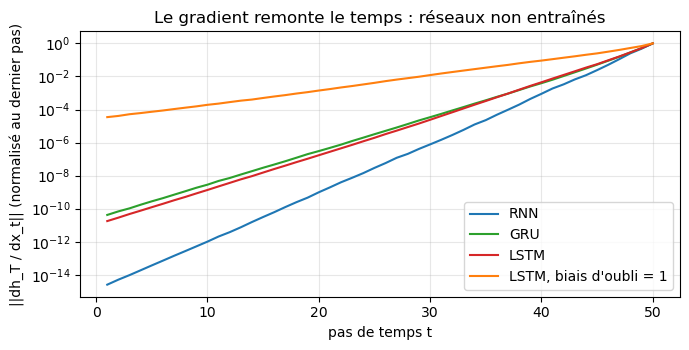

In [12]:
def normes_gradient(cell, T=50, d=64, h=128, n=30, graine=0, biais_oubli=None):
    g = torch.Generator().manual_seed(graine)
    torch.manual_seed(graine)
    modele = CLASSES[cell](d, h, batch_first=True)
    if biais_oubli is not None:                      # LSTM : biais de la porte d'oubli (blocs ordonnés i, f, g, o)
        with torch.no_grad():
            modele.bias_ih_l0[h:2 * h].fill_(biais_oubli); modele.bias_hh_l0[h:2 * h].zero_()
    cumul = torch.zeros(T)
    for _ in range(n):
        x = torch.randn(1, T, d, generator=g).requires_grad_(True)
        sortie, _ = modele(x)
        sortie[0, -1].sum().backward()
        cumul += x.grad[0].norm(dim=1)
    return (cumul / n).numpy()

T_GRAD = 50
grads = {"RNN": normes_gradient("rnn"), "GRU": normes_gradient("gru"), "LSTM": normes_gradient("lstm"),
         "LSTM, biais d'oubli = 1": normes_gradient("lstm", biais_oubli=1.0)}
print("rapport entre le gradient au pas 1 et celui du dernier pas (plus c'est petit, plus il s'évanouit) :")
for nom, v in grads.items():
    print(f"  {nom:24s} : {v[0] / v[-1]:.1e}   (pas 25 : {v[24] / v[-1]:.1e})")

fig, ax = plt.subplots(figsize=(7, 3.6))
for (nom, v), coul in zip(grads.items(), ("tab:blue", "tab:green", "tab:red", "tab:orange")):
    ax.semilogy(range(1, T_GRAD + 1), v / v[-1], label=nom, color=coul)
ax.set_xlabel("pas de temps t"); ax.set_ylabel("||dh_T / dx_t|| (normalisé au dernier pas)"); ax.legend()
ax.set_title("Le gradient remonte le temps : réseaux non entraînés")
plt.tight_layout(); plt.show()

**À observer.** Avec l'initialisation par défaut, le GRU et le LSTM font beaucoup mieux que le RNN simple, mais leur gradient s'évanouit encore sur 50 pas. Le **biais d'oubli à 1** fait gagner des ordres de grandeur supplémentaires au LSTM : les portes aident, à condition de bien les initialiser. Sur des séquences de 10 mots, ce défaut reste sans conséquence (voir B4).

### B4. RNN, LSTM, GRU sur MASSIVE fr-FR

Le même classifieur, avec trois cellules récurrentes : `Embedding(V, 64)` → cellule (état caché de 128) → `Dropout(0,3)` → `Linear(128, 60)`. L'état au **dernier mot réel** de la phrase alimente le classifieur. Entraînement avec Adam ($\eta = 2\times 10^{-3}$), lots de 64, arrêt précoce sur l'exactitude du `dev` (patience 4), 3 graines par cellule.

**Mesures** : exactitude (*accuracy*) sur les 2 974 phrases du `test`, puis sur les 220 phrases `iot_*` du `test` (la prédiction reste choisie parmi les **60** intentions), nombre de paramètres et temps d'entraînement.

In [13]:
class Classifieur(nn.Module):
    def __init__(self, V, cell, d=64, h=128, n_classes=60, p=0.3):
        super().__init__()
        self.emb = nn.Embedding(V, d, padding_idx=0)
        self.rnn = CLASSES[cell](d, h, batch_first=True)
        self.drop = nn.Dropout(p)
        self.out = nn.Linear(h, n_classes)

    def forward(self, x, longueurs):
        sortie, _ = self.rnn(self.emb(x))
        dernier = sortie[torch.arange(len(x), device=x.device), longueurs - 1]   # état au dernier mot réel
        return self.out(self.drop(dernier))

def exactitude(modele, X, L, y, masque=None):
    modele.eval()
    with torch.no_grad():
        pred = torch.cat([modele(X[i:i + 512].to(DEVICE), L[i:i + 512].to(DEVICE)).argmax(1).cpu()
                          for i in range(0, len(X), 512)])
    ok = (pred == y)
    return (ok.float().mean().item() if masque is None else ok[masque].float().mean().item()), pred

def entrainer(cell, graine, epoques_max=25, patience=4, lr=2e-3, lot=64):
    torch.manual_seed(graine)
    modele = Classifieur(len(vocab), cell).to(DEVICE)
    opt = torch.optim.Adam(modele.parameters(), lr=lr)
    meilleur, meilleure_ep, etat, sans_progres = -1.0, 0, None, 0
    t0 = time.time()
    for ep in range(1, epoques_max + 1):
        modele.train()
        perm = torch.randperm(len(Xtr))
        for i in range(0, len(perm), lot):
            idx = perm[i:i + lot]
            perte = F.cross_entropy(modele(Xtr[idx].to(DEVICE), Ltr[idx].to(DEVICE)), ytr[idx].to(DEVICE))
            opt.zero_grad(); perte.backward()
            nn.utils.clip_grad_norm_(modele.parameters(), 5.0)
            opt.step()
        acc_dev, _ = exactitude(modele, Xdv, Ldv, ydv)
        if acc_dev > meilleur:
            meilleur, meilleure_ep, sans_progres = acc_dev, ep, 0
            etat = {k: v.detach().clone() for k, v in modele.state_dict().items()}
        else:
            sans_progres += 1
            if sans_progres >= patience:
                break
    duree = time.time() - t0
    modele.load_state_dict(etat)
    acc_te, pred = exactitude(modele, Xte, Lte, yte)
    acc_iot, _ = exactitude(modele, Xte, Lte, yte, masque_iot)
    return dict(cell=cell.upper(), graine=graine, dev=meilleur, test=acc_te, iot=acc_iot, epoque=meilleure_ep,
                epoques=ep, duree=duree, params=nb_params(modele), params_rec=nb_params(modele.rnn)), modele, pred

resultats, modeles, preds = [], {}, {}
for cell in ("rnn", "lstm", "gru"):
    for graine in (0, 1, 2):
        r, m, p = entrainer(cell, graine)
        resultats.append(r); modeles[(cell, graine)] = m; preds[(cell, graine)] = p
        print(f"{r['cell']:5s} graine {graine} : dev {r['dev']:.3f}  test {r['test']:.3f}  iot_* {r['iot']:.3f}  "
              f"meilleure époque {r['epoque']:2d}/{r['epoques']:2d}  {r['duree']:5.1f} s")

RNN   graine 0 : dev 0.726  test 0.714  iot_* 0.773  meilleure époque 18/22   43.2 s


RNN   graine 1 : dev 0.735  test 0.714  iot_* 0.700  meilleure époque 14/18   35.7 s


RNN   graine 2 : dev 0.739  test 0.731  iot_* 0.759  meilleure époque 22/25   49.3 s


LSTM  graine 0 : dev 0.782  test 0.762  iot_* 0.791  meilleure époque 14/18   19.8 s


LSTM  graine 1 : dev 0.794  test 0.772  iot_* 0.795  meilleure époque 13/17   18.6 s


LSTM  graine 2 : dev 0.789  test 0.773  iot_* 0.791  meilleure époque 22/25   27.9 s


GRU   graine 0 : dev 0.773  test 0.770  iot_* 0.786  meilleure époque  7/11   35.5 s


GRU   graine 1 : dev 0.797  test 0.778  iot_* 0.795  meilleure époque 12/16   52.0 s


GRU   graine 2 : dev 0.789  test 0.778  iot_* 0.768  meilleure époque 15/19   63.7 s


Moyenne de 3 graines (± écart-type), périphérique mps. Paramètres totaux, dont cellule récurrente ; epoques = époque du meilleur score dev :
      params  params_rec        test       iot_*  epoques
cell                                                     
RNN   420412       24832  72.0 ± 1.0  74.4 ± 3.9     18.0
LSTM  494908       99328  76.9 ± 0.6  79.2 ± 0.3     16.3
GRU   470076       74496  77.5 ± 0.4  78.3 ± 1.4     11.3


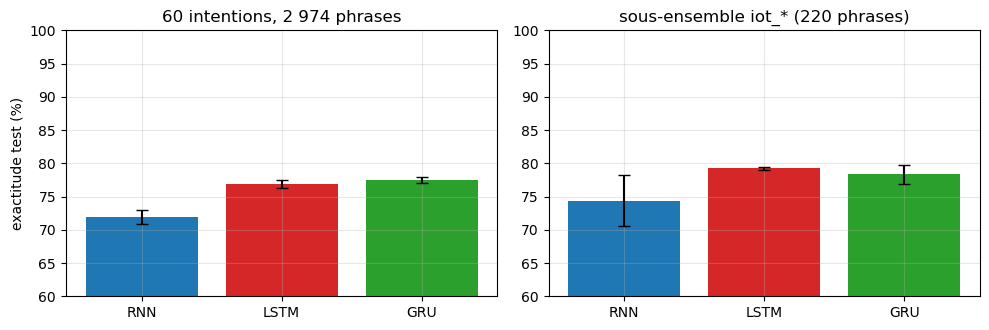

In [14]:
res = pd.DataFrame(resultats)
tab = res.groupby("cell", sort=False).agg(params=("params", "first"), params_rec=("params_rec", "first"),
                                         test_moy=("test", "mean"), test_std=("test", "std"),
                                         iot_moy=("iot", "mean"), iot_std=("iot", "std"),
                                         epoques=("epoque", "mean"), duree_par_ep=("duree", "sum"))
tab["duree_par_ep"] = res.groupby("cell", sort=False).apply(lambda g: g.duree.sum() / g.epoques.sum())
tab["test"] = [f"{100 * m:.1f} ± {100 * s:.1f}" for m, s in zip(tab.test_moy, tab.test_std)]
tab["iot_*"] = [f"{100 * m:.1f} ± {100 * s:.1f}" for m, s in zip(tab.iot_moy, tab.iot_std)]
print(f"Moyenne de 3 graines (± écart-type), périphérique {DEVICE}. Paramètres totaux, dont cellule récurrente ; epoques = époque du meilleur score dev :")
print(tab[["params", "params_rec", "test", "iot_*", "epoques"]].round({"epoques": 1}).to_string())

fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
ax[0].bar(tab.index, 100 * tab.test_moy, yerr=100 * tab.test_std, color=["tab:blue", "tab:red", "tab:green"], capsize=4)
ax[0].set_ylim(60, 100); ax[0].set_ylabel("exactitude test (%)"); ax[0].set_title("60 intentions, 2 974 phrases")
ax[1].bar(tab.index, 100 * tab.iot_moy, yerr=100 * tab.iot_std, color=["tab:blue", "tab:red", "tab:green"], capsize=4)
ax[1].set_ylim(60, 100); ax[1].set_title("sous-ensemble iot_* (220 phrases)")
plt.tight_layout(); plt.show()

**Observations à faire** : le LSTM et le GRU battent-ils le RNN simple ? De combien ? Le GRU, avec 25 % de paramètres en moins dans la cellule, fait-il aussi bien que le LSTM ? Comparez ensuite les temps (cellule suivante) : la récurrence est séquentielle, elle ne se parallélise pas sur le temps.

#### Temps d'entraînement : un banc d'essai sur CPU

Les temps mesurés pendant l'entraînement dépendent du GPU et de l'implémentation (sur Apple MPS, par exemple, le GRU est plus lent que le LSTM, ce qui n'a rien de général). Pour comparer les cellules **à armes égales**, on chronomètre ici un pas d'entraînement complet (propagation avant, rétropropagation, Adam) sur un lot de 64 phrases, sur CPU, 1 fil d'exécution.

In [15]:
def ms_par_lot(cell, n=40, lot=64):
    torch.manual_seed(0)
    torch.set_num_threads(1)
    modele = Classifieur(len(vocab), cell)                 # sur CPU
    opt = torch.optim.Adam(modele.parameters(), lr=2e-3)
    x, l, y = Xtr[:lot], Ltr[:lot], ytr[:lot]
    def pas():
        perte = F.cross_entropy(modele(x, l), y)
        opt.zero_grad(); perte.backward(); opt.step()
    for _ in range(5):
        pas()
    t0 = time.perf_counter()
    for _ in range(n):
        pas()
    return 1000 * (time.perf_counter() - t0) / n

LOTS_PAR_EPOQUE = int(np.ceil(len(Xtr) / 64))
bench = {c: ms_par_lot(c) for c in ("rnn", "lstm", "gru")}
torch.set_num_threads(max(1, os.cpu_count() or 1))
print(f"Pas d'entraînement sur CPU, lot de 64 phrases ({LOTS_PAR_EPOQUE} lots par époque) :")
for c, ms in bench.items():
    print(f"  {c.upper():5s} : {ms:6.1f} ms par lot  ->  {ms * LOTS_PAR_EPOQUE / 1000:5.1f} s par époque   (x{ms / bench['rnn']:.1f} par rapport au RNN)")

Pas d'entraînement sur CPU, lot de 64 phrases (180 lots par époque) :
  RNN   :    3.0 ms par lot  ->    0.5 s par époque   (x1.0 par rapport au RNN)
  LSTM  :    9.5 ms par lot  ->    1.7 s par époque   (x3.2 par rapport au RNN)
  GRU   :    7.3 ms par lot  ->    1.3 s par époque   (x2.4 par rapport au RNN)


#### Où se trompe-t-on ? Les confusions du GRU sur les intentions `iot_*`

In [16]:
p = preds[("gru", 0)].numpy(); y = yte.numpy()
conf = collections.Counter((INTENTS[a], INTENTS[b]) for a, b in zip(y, p) if a != b and INTENTS[a].startswith("iot_"))
print("erreurs sur iot_* (GRU, graine 0) :", sum(conf.values()), "sur", int(masque_iot.sum()))
for (vrai, predit), n in conf.most_common(6):
    print(f"  {n:2d} x  vrai = {vrai:18s} prédit = {predit}")

erreurs sur iot_* (GRU, graine 0) : 47 sur 220
   3 x  vrai = iot_hue_lightdim   prédit = iot_hue_lightchange
   3 x  vrai = iot_hue_lightup    prédit = iot_hue_lighton
   3 x  vrai = iot_wemo_off       prédit = iot_hue_lightoff
   2 x  vrai = iot_hue_lighton    prédit = iot_hue_lightoff
   2 x  vrai = iot_hue_lightup    prédit = iot_hue_lightchange
   2 x  vrai = iot_hue_lightup    prédit = play_audiobook


#### Les embeddings appris : voisins les plus proches

Après entraînement, la matrice d'embeddings du GRU contient un vecteur de 64 dimensions par mot. On cherche les voisins (cosinus) de quelques mots, parmi les mots vus au moins 5 fois dans le train. Le corpus est petit (11 514 phrases) : les embeddings sont appris **pour la tâche** et non pour la langue en général, donc leurs voisins n'ont pas toujours de sens évident. C'est la limite des embeddings appris de zéro, que les modèles pré-entraînés de la séance 5 corrigent.

In [17]:
E_gru = modeles[("gru", 0)].emb.weight.detach().cpu().numpy()
frequents = [i for i, m in enumerate(vocab) if i > 1 and cpt[m] >= 5]
En = E_gru / (np.linalg.norm(E_gru, axis=1, keepdims=True) + 1e-9)
for mot in ["allume", "éteins", "salon", "musique", "réveille"]:
    if mot not in MOT2ID:
        continue
    sims = En[frequents] @ En[MOT2ID[mot]]
    voisins = [(vocab[frequents[k]], sims[k]) for k in np.argsort(-sims)[1:6]]
    print(f"{mot:9s} -> " + ", ".join(f"{m} ({s:.2f})" for m, s in voisins))

allume    -> messagerie (0.43), populaire (0.43), uniquement (0.38), comme (0.35), quatre (0.35)
éteins    -> amy (0.38), cette (0.35), son (0.33), viens (0.31), vrai (0.31)
salon     -> classique (0.39), domino (0.37), monde (0.34), lyon (0.34), début (0.32)
musique   -> rappelez (0.38), écouté (0.38), jazz (0.35), nettoyeur (0.34), réglez (0.34)
réveille  -> récupérer (0.44), nuit (0.37), valeur (0.37), vous (0.35), passe (0.34)


### B5. Un LSTM par caractères sur le noyau FreeRTOS

Un modèle de langage prédit le **caractère suivant**. On l'entraîne sur les sources du noyau FreeRTOS (`tasks.c`, `queue.c`, `list.c`, `timers.c`, `event_groups.c`, `stream_buffer.c`, licence MIT), puis on lui fait **écrire du C** en variant la **température** $T$ : $T$ faible, texte sûr et répétitif ; $T$ élevé, texte varié mais plus souvent faux. C'est le mécanisme d'échantillonnage des LLM (séance 6).

**Repli** : si GitHub est indisponible, un court extrait C de secours est utilisé et les résultats sont peu représentatifs.

In [18]:
URL_RTOS = "https://raw.githubusercontent.com/FreeRTOS/FreeRTOS-Kernel/main/"
SOURCES = ["tasks.c", "queue.c", "list.c", "timers.c", "event_groups.c", "stream_buffer.c"]
SECOURS = """
void vListInsertEnd( List_t * const pxList, ListItem_t * const pxNewListItem )
{
    ListItem_t * const pxIndex = pxList->pxIndex;
    pxNewListItem->pxNext = pxIndex;
    pxNewListItem->pxPrevious = pxIndex->pxPrevious;
    pxIndex->pxPrevious->pxNext = pxNewListItem;
    pxIndex->pxPrevious = pxNewListItem;
    pxNewListItem->pxContainer = pxList;
    ( pxList->uxNumberOfItems )++;
}
BaseType_t xQueueSend( QueueHandle_t xQueue, const void * pvItemToQueue, TickType_t xTicksToWait )
{
    if( uxMessagesWaiting < pxQueue->uxLength )
    {
        prvCopyDataToQueue( pxQueue, pvItemToQueue, xCopyPosition );
        xReturn = pdPASS;
    }
    else
    {
        xReturn = errQUEUE_FULL;
    }
    return xReturn;
}
""" * 20

def charger_rtos():
    morceaux, ok = [], True
    for nom in SOURCES:
        chemin = os.path.join(CACHE, nom)
        if not os.path.exists(chemin):
            try:
                with urllib.request.urlopen(URL_RTOS + nom, timeout=60) as r:
                    open(chemin, "wb").write(r.read())
            except Exception as e:
                print("Téléchargement impossible :", nom, type(e).__name__); ok = False; break
        morceaux.append(open(chemin, encoding="utf-8", errors="replace").read())
    return ("\n".join(morceaux), "sources FreeRTOS-Kernel") if ok else (SECOURS, "extrait de secours")

corpus, origine = charger_rtos()
corpus = "".join(ch if (ch in "\n\t" or 32 <= ord(ch) < 127) else "?" for ch in corpus)
assert "xTaskBoostPriorityFromISR" not in corpus     # cette fonction n'existe pas dans FreeRTOS (elle sert à la séance 6)
CARS = sorted(set(corpus)); C2I = {c: i for i, c in enumerate(CARS)}
data = torch.tensor([C2I[c] for c in corpus])
coupe = int(0.9 * len(data))
print(f"{origine} : {len(corpus):,} caractères, {len(CARS)} symboles distincts".replace(",", " "))
print("extrait :", repr(corpus[3000:3150]))
H_CAR = 256 if DEVICE.type != "cpu" else 128
N_ETAPES = 800 if DEVICE.type != "cpu" else 300
print(f"état caché {H_CAR}, {N_ETAPES} étapes d'entraînement")

sources FreeRTOS-Kernel : 676 216 caractères  93 symboles distincts
extrait : 'he kernel. */\n    #include <stdio.h>\n#endif /* configUSE_STATS_FORMATTING_FUNCTIONS == 1 ) */\n\n#if ( configUSE_PREEMPTION == 0 )\n\n/* If the cooperativ'
état caché 256, 800 étapes d'entraînement


In [19]:
class ModeleCar(nn.Module):
    def __init__(self, V, d=64, h=256, couches=2, p=0.3):
        super().__init__()
        self.emb = nn.Embedding(V, d)
        self.lstm = nn.LSTM(d, h, num_layers=couches, batch_first=True, dropout=p)
        self.out = nn.Linear(h, V)
    def forward(self, x, etat=None):
        o, etat = self.lstm(self.emb(x), etat)
        return self.out(o), etat

def lot_car(source, taille=64, longueur=128):
    debuts = torch.randint(0, len(source) - longueur - 1, (taille,))
    x = torch.stack([source[i:i + longueur] for i in debuts])
    y = torch.stack([source[i + 1:i + longueur + 1] for i in debuts])
    return x.to(DEVICE), y.to(DEVICE)

def bpc_val(modele, n_lots=20):
    modele.eval()
    g = torch.manual_seed(123)
    with torch.no_grad():
        pertes = []
        for _ in range(n_lots):
            x, y = lot_car(data[coupe:])
            sortie, _ = modele(x)
            pertes.append(F.cross_entropy(sortie.reshape(-1, len(CARS)), y.reshape(-1)).item())
    modele.train()
    return float(np.mean(pertes)) / math.log(2)

torch.manual_seed(SEED)
modele_car = ModeleCar(len(CARS), h=H_CAR).to(DEVICE)
opt = torch.optim.Adam(modele_car.parameters(), lr=3e-3)
planif = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=N_ETAPES)
print("paramètres :", f"{nb_params(modele_car):,}".replace(",", " "))
print(f"référence : choisir au hasard parmi {len(CARS)} symboles = {math.log2(len(CARS)):.2f} bits par caractère")
courbe, t0 = [], time.time()
for etape in range(1, N_ETAPES + 1):
    x, y = lot_car(data[:coupe])
    sortie, _ = modele_car(x)
    perte = F.cross_entropy(sortie.reshape(-1, len(CARS)), y.reshape(-1))
    opt.zero_grad(); perte.backward()
    nn.utils.clip_grad_norm_(modele_car.parameters(), 1.0)      # écrête les gradients : garde-fou contre l'explosion
    opt.step(); planif.step()
    if etape % (N_ETAPES // 8) == 0:
        courbe.append((etape, perte.item() / math.log(2), bpc_val(modele_car)))
        print(f"étape {etape:5d} : bpc entraînement {courbe[-1][1]:.2f}   bpc validation {courbe[-1][2]:.2f}   ({time.time() - t0:.0f} s)")
BPC_FINAL = courbe[-1][2]

paramètres : 885 917
référence : choisir au hasard parmi 93 symboles = 6.54 bits par caractère


étape   100 : bpc entraînement 1.84   bpc validation 2.43   (2 s)


étape   200 : bpc entraînement 1.43   bpc validation 1.84   (5 s)


étape   300 : bpc entraînement 1.20   bpc validation 1.69   (7 s)


étape   400 : bpc entraînement 1.08   bpc validation 1.65   (9 s)


étape   500 : bpc entraînement 1.01   bpc validation 1.64   (12 s)


étape   600 : bpc entraînement 0.97   bpc validation 1.63   (14 s)


étape   700 : bpc entraînement 0.94   bpc validation 1.63   (16 s)


étape   800 : bpc entraînement 0.93   bpc validation 1.63   (19 s)


#### Générer du code C : l'effet de la température

On donne une amorce, et le modèle écrit la suite caractère par caractère : à chaque pas, on divise les logits par $T$, on applique le softmax, et on **tire** le caractère suivant. Pour chiffrer l'effet, on mesure sur 5 textes de 1 500 caractères par température :

- la part d'**identifiants** générés (mots de plus de 3 lettres) qui **existent** dans le corpus FreeRTOS ;
- la **diversité** : nombre d'identifiants distincts divisé par le nombre d'identifiants générés (proche de 0, le texte se répète).

In [20]:
@torch.no_grad()
def generer(amorce, n, temperature, graine):
    modele_car.eval()
    g = torch.Generator(device="cpu").manual_seed(graine)
    x = torch.tensor([[C2I.get(c, 0) for c in amorce]], device=DEVICE)
    sortie, etat = modele_car(x)
    texte = amorce
    for _ in range(n):
        p = F.softmax(sortie[0, -1].float().cpu() / temperature, dim=0)
        k = int(torch.multinomial(p, 1, generator=g))
        texte += CARS[k]
        sortie, etat = modele_car(torch.tensor([[k]], device=DEVICE), etat)
    modele_car.train()
    return texte

AMORCE = "BaseType_t xQueueSend( QueueHandle_t xQueue,"
IDENT = re.compile(r"[A-Za-z_][A-Za-z0-9_]{3,}")
connus = set(IDENT.findall(corpus))
lignes = []
for T_ in (0.2, 0.7, 1.0, 1.4):
    ids_tot, ids_connus = [], 0
    for graine in range(5):
        ids = IDENT.findall(generer(AMORCE, 1500, T_, graine)[len(AMORCE):])
        ids_tot += ids; ids_connus += sum(i in connus for i in ids)
    n_id = max(1, len(ids_tot))
    lignes.append(dict(T=T_, identifiants=len(ids_tot), existants=ids_connus / n_id, diversite=len(set(ids_tot)) / n_id))
tab_T = pd.DataFrame(lignes)
tab_T["existants"] = tab_T.existants.map("{:.1%}".format); tab_T["diversite"] = tab_T.diversite.map("{:.2f}".format)
print(tab_T.to_string(index=False))
print("\nFonction inventée générée ? ", any("xTaskBoostPriorityFromISR" in generer(AMORCE, 1500, 1.4, s) for s in range(5)))

  T  identifiants existants diversite
0.2            13     92.3%      0.46
0.7           380     60.0%      0.64
1.0           451     32.6%      0.86
1.4           528      9.1%      0.98



Fonction inventée générée ?  False


In [21]:
for T_ in (0.2, 0.7, 1.4):
    print(f"\n===== température {T_} =====")
    print(generer(AMORCE, 400, T_, 0))


===== température 0.2 =====


BaseType_t xQueueSend( QueueHandle_t xQueue, pxCurrentTCB->uxPriority = pxTCB->uxPriority );
                                                                                                                                                                                                                                                                                                                                                               

===== température 0.7 =====


BaseType_t xQueueSend( QueueHandle_t xQueue, pcName[ xCoreAffition();
                                                                                                        brete the prations is the state task state is the sto the list lower then the currently be exter...w.pwitely wethen the task is detent. state this task
                 * the current the task ablow the priority by the staticate then the past check at alter with other st

===== température 1.4 =====


BaseType_t xQueueSend( QueueHandle_t xQueue,lectultode,; tho; * "POmtIstlucTing-44Wnot( pxNlow;fharolochedYilicateListIt( mtCOlTask()+oc/PeptherThe eph0eO1trum,MegFromIgtToPabion,allechSaze )
    TFRLERTOSSAAPDIED = &1 UBafief2codiFarity6nglocCatchOut( 0 rittCslata();

    #ewar queletQuexExpitentio();
 t if tmiblT2IST OFARTIWAPINPROF THO" WE'T WSHATFSCHIATNA, IPRY TH ETHER WIWWELPABINLEN; FRHOAY > 1 ];
    ( TicsType_t ulItemToE,;LytctCon 


**Observations à faire** : à $T = 0{,}2$, le texte ressemble à du C, mais se répète (souvent, il s'enlise dans des espaces d'indentation) ; à $T = 1{,}4$, il invente des identifiants qui n'existent pas dans FreeRTOS. Un modèle de moins d'un million de paramètres produit du C **plausible**, jamais **vérifié** : c'est le mécanisme de l'hallucination, que l'on retrouve avec les LLM à la séance 6.

### B6. Et sur cible embarquée ?

Les trois classifieurs du B4 ($d = 64$, $h = 128$) et le LSTM de la diapositive ($d = 16$, $h = 32$) face à la Flash et à la SRAM du STM32F446. L'embedding de MASSIVE domine la taille : il se stocke en int8 et se lit par **index** (un accès par mot, aucun calcul).

In [22]:
print(f"{'modèle':44s}{'paramètres':>12s}{'float32':>11s}{'int8':>9s}{'% Flash (int8)':>16s}")
for nom, n in [("Classifieur GRU (V = %d, d = 64, h = 128)" % len(vocab), int(tab.loc['GRU', 'params'])),
               ("  dont cellule GRU seule", int(tab.loc['GRU', 'params_rec'])),
               ("  dont embeddings", len(vocab) * 64),
               ("LSTM de la diapositive (16 -> 32)", 4 * 32 * (16 + 32 + 2))]:
    n_txt = f"{n:,d}".replace(",", " ")
    print(f"{nom:44s}{n_txt:>12s}{4 * n / 1000:9.1f} ko{n / 1000:7.1f} ko{n / FLASH:15.1%}")

mac_gru = 3 * 128 * (64 + 128)
print(f"\nMAC par mot du GRU (d = 64, h = 128) : {mac_gru} ; pour 10 mots : {10 * mac_gru} MAC, "
      f"soit {10 * mac_gru * 2 / FREQ * 1e3:.1f} à {10 * mac_gru * 4 / FREQ * 1e3:.1f} ms à 180 MHz (2 à 4 cycles par MAC)")

modèle                                        paramètres    float32     int8  % Flash (int8)
Classifieur GRU (V = 6060, d = 64, h = 128)      470 076   1880.3 ko  470.1 ko          89.7%
  dont cellule GRU seule                          74 496    298.0 ko   74.5 ko          14.2%
  dont embeddings                                387 840   1551.4 ko  387.8 ko          74.0%
LSTM de la diapositive (16 -> 32)                  6 400     25.6 ko    6.4 ko           1.2%

MAC par mot du GRU (d = 64, h = 128) : 73728 ; pour 10 mots : 737280 MAC, soit 8.2 à 16.4 ms à 180 MHz (2 à 4 cycles par MAC)


## Partie C — Exercices de validation

Chaque fonction ci-dessous renvoie `None` : le vérificateur affiche alors **« À compléter »**. Complétez-les, puis relancez `verifier_tout()`. Le corrigé est à la fin du notebook : essayez d'abord !

In [23]:
def verifier(nom, valeur, attendu, tol=1e-3):
    if valeur is None:
        print(f"{nom} : À compléter")
        return
    try:
        ok = np.allclose(np.asarray(valeur, dtype=float), np.asarray(attendu, dtype=float), atol=tol)
    except Exception:
        ok = False
    if ok:
        print(f"{nom} : Correct")
    else:
        print(f"{nom} : Incorrect (obtenu {np.round(np.asarray(valeur, dtype=float), 4)}, attendu {attendu})")

def verifier_tout():
    verifier("Exercice 1 — pas de RNN", rnn_pas(np.array([0.0, 1.0]), np.array([0.4621, 0.2913]), Wxh, Whh, np.zeros(2)), [-0.2785, 0.6612])
    verifier("Exercice 2 — paramètres LSTM (64, 128)", params_recurrent("lstm", 64, 128), 99328)
    verifier("Exercice 2 bis — paramètres GRU (16, 32)", params_recurrent("gru", 16, 32), 4800)
    r = lstm_pas(2.0, 0.0, 1.0, 1.0, 0.8)
    verifier("Exercice 3 — pas de LSTM (c, h)", None if r is None else list(r), [1.0854, 0.5813])
    verifier("Exercice 4 — contexte d'attention", attention_contexte([2.0, 1.0, 0.0], [[1, 0], [0, 1], [1, 1]]), [0.7553, 0.3348])
    verifier("Exercice 5 — MAC d'un LSTM sur 30 pas", mac_sequence("lstm", 16, 32, 30), 184320)
    verifier("Exercice 5 bis — MAC d'un GRU sur 10 pas", mac_sequence("gru", 64, 128, 10), 737280)

**Exercice 1 — Un pas de RNN.** Complétez `rnn_pas(x, h, Wxh, Whh, b)` : l'état suivant $\tanh(W_{xh}\mathbf{x} + W_{hh}\mathbf{h} + \mathbf{b})$. Vérification : le pas $t = 2$ de la partie A3.

In [24]:
def rnn_pas(x, h, Wxh, Whh, b):
    # À compléter
    return None

**Exercice 2 — Compter les paramètres.** Complétez `params_recurrent(cell, d, h)` pour `cell` valant `"rnn"`, `"gru"` ou `"lstm"` (convention PyTorch, deux vecteurs de biais par porte). Puis, en dehors du vérificateur : combien de paramètres pour un LSTM bidirectionnel de même taille ?

In [25]:
def params_recurrent(cell, d, h):
    # À compléter
    return None

**Exercice 3 — Un pas de LSTM à une unité.** Complétez `lstm_pas(zf, zi, zo, zg, c_prev)` : à partir des pré-activations des trois portes et du candidat, elle renvoie le couple `(c, h)`.

In [26]:
def lstm_pas(zf, zi, zo, zg, c_prev):
    # À compléter : renvoyer (c, h)
    return None

**Exercice 4 — Contexte d'attention.** Complétez `attention_contexte(scores, H)` : le vecteur $\sum_j \alpha_j \mathbf{h}_j$ avec $\alpha = \mathrm{softmax}(\text{scores})$. Puis, en dehors du vérificateur : que devient le contexte si les scores valent $(10, 0, 0)$ ?

In [27]:
def attention_contexte(scores, H):
    # À compléter
    return None

**Exercice 5 — MAC d'une séquence.** Complétez `mac_sequence(cell, d, h, T)` : le nombre de multiplications-accumulations pour traiter $T$ pas de temps (on ne compte que les produits matriciels, pas les non-linéarités). Puis, en dehors du vérificateur : la latence sur le STM32F446 à 180 MHz et 3 cycles par MAC.

In [28]:
def mac_sequence(cell, d, h, T):
    # À compléter
    return None

In [29]:
verifier_tout()

Exercice 1 — pas de RNN : À compléter
Exercice 2 — paramètres LSTM (64, 128) : À compléter
Exercice 2 bis — paramètres GRU (16, 32) : À compléter
Exercice 3 — pas de LSTM (c, h) : À compléter
Exercice 4 — contexte d'attention : À compléter
Exercice 5 — MAC d'un LSTM sur 30 pas : À compléter
Exercice 5 bis — MAC d'un GRU sur 10 pas : À compléter


## Corrigé

Essayez d'abord les exercices ! Cette section définit les solutions, puis relance le vérificateur.

In [30]:
def rnn_pas(x, h, Wxh, Whh, b):
    return np.tanh(Wxh @ np.asarray(x, dtype=float) + Whh @ np.asarray(h, dtype=float) + b)

def params_recurrent(cell, d, h):
    return FACTEUR[cell] * h * (d + h + 2)            # bidirectionnel : le double, car deux cellules (aller et retour)

def lstm_pas(zf, zi, zo, zg, c_prev):
    f, i, o, g = sigmoide(zf), sigmoide(zi), sigmoide(zo), np.tanh(zg)
    c = f * c_prev + i * g
    return c, o * np.tanh(c)

def attention_contexte(scores, H):
    return softmax_np(scores) @ np.asarray(H, dtype=float)     # scores (10, 0, 0) : alpha ≈ (1, 0, 0), le contexte est h_1

def mac_sequence(cell, d, h, T):
    return FACTEUR[cell] * h * (d + h) * T             # LSTM 16 -> 32 sur 30 pas : 184 320 MAC, soit 3,1 ms à 3 cycles par MAC

verifier_tout()

Exercice 1 — pas de RNN : Correct
Exercice 2 — paramètres LSTM (64, 128) : Correct
Exercice 2 bis — paramètres GRU (16, 32) : Correct
Exercice 3 — pas de LSTM (c, h) : Correct
Exercice 4 — contexte d'attention : Correct
Exercice 5 — MAC d'un LSTM sur 30 pas : Correct
Exercice 5 bis — MAC d'un GRU sur 10 pas : Correct


## Pour aller plus loin

- Ajoutez `bidirectional=True` au classifieur et concaténez les deux états : gagne-t-on en exactitude ? Combien de paramètres de plus ?
- Remplacez le dernier état par la **moyenne** des états sur les mots réels (*mean pooling*).
- Entraînez le modèle par caractères avec `h = 512` ou 3 couches : le bpc de validation baisse-t-il ? À partir de quand sur-apprend-on ?
- Reprenez le MLP à fenêtre de 30 cycles de la séance 3 (C-MAPSS) et remplacez-le par un GRU de 32 unités : la RMSE baisse-t-elle ?

## Références

- Elman (1990), *Finding structure in time* ; Hochreiter et Schmidhuber (1997), *Long short-term memory* ; Gers et al. (2000), porte d'oubli ; Cho et al. (2014), GRU.
- Pascanu et al. (2013), *On the difficulty of training recurrent neural networks* (écrêtage du gradient) ; Bahdanau et al. (2014), attention.
- Sennrich et al. (2016), BPE ; FitzGerald et al. (2022), *MASSIVE* ; Du et al. (2017), *DeepLog*.

In [31]:
print(f"Durée d'exécution du notebook : {time.time() - T0:.0f} s")

Durée d'exécution du notebook : 388 s
